# 03 · Versión B: afinar el VLM con LoRA

**Fine-tuning** es seguir entrenando un modelo ya entrenado con nuestros datos para que aprenda **nuestra** tarea. Entrenar los 256 M de parámetros sería lento y pesado; con **LoRA** (*Low-Rank Adaptation*) no tocamos los pesos originales:

- Cada matriz de pesos grande `W` (por ejemplo, 576 × 576) se queda **congelada**.
- A su lado se añaden dos matrices pequeñas `A` (576 × r) y `B` (r × 576), con `r` = 16. La capa calcula `W·x + B·A·x`.
- Solo se entrenan `A` y `B`: menos del 1 % de los parámetros. Al terminar se guarda **solo el adaptador** (unos pocos MB), que se «enchufa» al modelo base.

Además **congelamos el codificador de imagen y el conector**: ya saben ver; lo que hay que enseñar es a **escribir** los números. LoRA va solo en la atención del modelo de lenguaje (`q_proj`, `k_proj`, `v_proj`, `o_proj`).

Entrada: `parejas/`. Salida: `adaptador/`, `resultados/pred_B.jsonl`, `resultados/metricas_B.json` y un run en MLflow (base temporal dentro de la carpeta de trabajo).

In [1]:
import os
N_EJEMPLOS = int(os.environ.get("ESTILO_N_EJEMPLOS", "60"))
EPOCAS = int(os.environ.get("ESTILO_EPOCAS", "2"))
RESOLUCION = int(os.environ.get("ESTILO_RESOLUCION", "224"))
MODELO = os.environ.get("ESTILO_MODELO", "HuggingFaceTB/SmolVLM-256M-Instruct")
CARPETA_TRABAJO = os.environ.get("ESTILO_TRABAJO", "_trabajo")
TAM_LOTE = 4
TASA_APRENDIZAJE = 5e-4
RANGO_LORA = 16

In [2]:
import json, random
import numpy as np
import matplotlib.pyplot as plt
import comun_estilo as ce

plt.rcParams["figure.dpi"] = 55
trabajo = ce.carpeta_trabajo(CARPETA_TRABAJO)
hilos = ce.limitar_hilos()
import torch, transformers, peft
from peft import LoraConfig, get_peft_model
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| hilos:", hilos)
torch.manual_seed(0); random.seed(0)

proc, vlm = ce.cargar_vlm(MODELO)
for p in vlm.parameters():          # 1) congelamos TODO el modelo...
    p.requires_grad = False
config = LoraConfig(r=RANGO_LORA, lora_alpha=2 * RANGO_LORA, lora_dropout=0.05,
                    target_modules=r".*text_model.*\.(q_proj|k_proj|v_proj|o_proj)")
modelo = get_peft_model(vlm, config)  # 2) ...y añadimos las matrices LoRA, que sí se entrenan
modelo.print_trainable_parameters()

torch 2.15.0+cpu | transformers 5.23.0 | peft 0.22.0 | hilos: 12


trainable params: 1,843,200 || all params: 258,328,128 || trainable%: 0.7135


## 1. Preparar los ejemplos

Cada ejemplo es: `<image>` + la orden corta `"Color edits as JSON."` + la respuesta correcta (el JSON). La pérdida solo se calcula sobre la respuesta: no queremos que aprenda a repetir el prompt.

**Truco de CPU:** como el codificador de imagen está congelado, sus «palabras de imagen» son siempre las mismas para cada foto. Las calculamos **una vez** aquí y las reutilizamos en todas las épocas.

In [3]:
train, val, test = (ce.leer_parejas(trabajo, p) for p in ("train", "val", "test"))
with ce.Cronometro() as c_prep:
    ej_train = [ce.preparar_ejemplo(proc, vlm, ce.abrir(trabajo, f["editada"]), f["ajustes"]) for f in train]
    ej_val = [ce.preparar_ejemplo(proc, vlm, ce.abrir(trabajo, f["editada"]), f["ajustes"]) for f in val]
n_resp = int((ej_train[0]["etiquetas"] != -100).sum())
print(f"{len(ej_train)} de entrenamiento y {len(ej_val)} de validación preparados en {c_prep.s:.0f} s")
print(f"Longitud de un ejemplo: {len(ej_train[0]['ids'])} tokens, de ellos {n_resp} de respuesta")
print("Texto de un ejemplo (sin las 64 palabras de imagen):")
print(proc.tokenizer.decode([t for t in ej_train[0]["ids"] if t != vlm.config.image_token_id]))

210 de entrenamiento y 30 de validación preparados en 530 s
Longitud de un ejemplo: 135 tokens, de ellos 55 de respuesta
Texto de un ejemplo (sin las 64 palabras de imagen):
<|im_start|>User:<fake_token_around_image><global-img><fake_token_around_image>Color edits as JSON.<end_of_utterance>
Assistant: {"exposicion": 0.13, "temperatura": -0.67, "tinte": -0.88, "contraste": 0.92, "saturacion": 1.02}<end_of_utterance>


## 2. Entrenar

Un bucle de entrenamiento normal de PyTorch: lote → pérdida → gradientes → paso del optimizador. La **pérdida** es la entropía cruzada de predecir cada token de la respuesta (cuanto más baja, más probable le parece la respuesta correcta). Al final de cada época medimos la pérdida en **validación**, que el modelo no usa para aprender.

Época 0: pérdida de validación 2.758


Época 1: pérdida de entrenamiento (último lote) 0.465, validación 0.479


Época 2: pérdida de entrenamiento (último lote) 0.474, validación 0.476


Época 3: pérdida de entrenamiento (último lote) 0.484, validación 0.475
Entrenamiento: 593 s, 159 pasos, 3.73 s por paso de 4 ejemplos


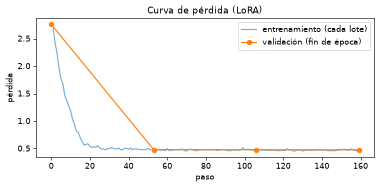

In [4]:
pad = proc.tokenizer.pad_token_id
optimizador = torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad], lr=TASA_APRENDIZAJE)

def perdida_val():
    modelo.eval()
    with torch.no_grad():
        return float(np.mean([modelo(**ce.lote(ej_val[i:i + 8], pad)).loss.item() for i in range(0, len(ej_val), 8)]))

historia = {"paso": [], "perdida": [], "epoca": [0], "perdida_val": [perdida_val()]}
print(f"Época 0: pérdida de validación {historia['perdida_val'][0]:.3f}")
with ce.Cronometro() as c_train:
    for epoca in range(1, EPOCAS + 1):
        modelo.train()
        random.shuffle(ej_train)
        for i in range(0, len(ej_train), TAM_LOTE):
            perdida = modelo(**ce.lote(ej_train[i:i + TAM_LOTE], pad)).loss
            perdida.backward(); optimizador.step(); optimizador.zero_grad()
            historia["paso"].append(len(historia["paso"]) + 1); historia["perdida"].append(perdida.item())
        historia["epoca"].append(epoca); historia["perdida_val"].append(perdida_val())
        print(f"Época {epoca}: pérdida de entrenamiento (último lote) {perdida.item():.3f}, "
              f"validación {historia['perdida_val'][-1]:.3f}")
pasos = len(historia["paso"])
print(f"Entrenamiento: {c_train.s:.0f} s, {pasos} pasos, {c_train.s / pasos:.2f} s por paso de {TAM_LOTE} ejemplos")

pasos_por_epoca = pasos / EPOCAS
plt.figure(figsize=(7, 3.5))
plt.plot(historia["paso"], historia["perdida"], alpha=0.6, label="entrenamiento (cada lote)")
plt.plot([e * pasos_por_epoca for e in historia["epoca"]], historia["perdida_val"], "o-", label="validación (fin de época)")
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.legend(); plt.title("Curva de pérdida (LoRA)")
plt.tight_layout(); os.makedirs("figuras", exist_ok=True); plt.savefig("figuras/03_curva_perdida.png", dpi=70); plt.show()

## 3. Guardar el adaptador y medir en test

Guardamos **solo** el adaptador LoRA. Luego, como haría la aplicación real, le damos a cada foto de test **la imagen** (ahora sí pasa por el codificador) y la orden corta, y leemos el JSON que escribe.

In [5]:
carpeta_adaptador = trabajo / "adaptador"
modelo.save_pretrained(carpeta_adaptador)
tam_adaptador = ce.tamano_mb(carpeta_adaptador / "adapter_model.safetensors")
from huggingface_hub import snapshot_download
tam_base = ce.tamano_mb(snapshot_download(MODELO, allow_patterns=["*.safetensors"]))
print(f"Adaptador: {tam_adaptador} MB  |  pesos del modelo base (safetensors): {tam_base} MB")

modelo.eval()
resultados, tiempos = [], []
for f in test:
    with ce.Cronometro() as c:
        respuesta = ce.preguntar(proc, modelo, ce.abrir(trabajo, f["editada"]), prompt=ce.PROMPT_CORTO)
    tiempos.append(c.s)
    pred, completo = ce.parsear(respuesta)
    resultados.append({"id": f["id"], "respuesta": respuesta, "pred": pred, "completo": completo})
(trabajo / "resultados").mkdir(exist_ok=True)
(trabajo / "resultados" / "pred_B.jsonl").write_text(
    "\n".join(json.dumps(r, ensure_ascii=False) for r in resultados), encoding="utf-8")

reales = [f["ajustes"] for f in test]
m = ce.error_por_ajuste([r["pred"] for r in resultados], reales)
neutro = ce.error_por_ajuste([ce.NEUTRO] * len(test), reales)
m.update(formato_correcto=float(np.mean([r["completo"] for r in resultados])),
         segundos_por_foto=float(np.mean(tiempos)), segundos_entrenamiento=c_train.s,
         segundos_preparacion=c_prep.s, adaptador_mb=tam_adaptador, base_mb=tam_base,
         memoria_pico_mb=ce.memoria_mb())
print(f"Formato correcto: {m['formato_correcto']:.0%}  |  {m['segundos_por_foto']:.2f} s por foto")
print(f"{'ajuste':12s} {'MAE':>6s} {'MAE norm.':>10s} {'neutro norm.':>13s}")
for k in ce.NOMBRES:
    print(f"{k:12s} {m['mae_'+k]:6.3f} {m['maen_'+k]:10.3f} {neutro['maen_'+k]:13.3f}")
print(f"{'MEDIA':12s} {'':6s} {m['mae_normalizado_medio']:10.3f} {neutro['mae_normalizado_medio']:13.3f}")
print("Memoria pico del proceso (MB):", m["memoria_pico_mb"])
(trabajo / "resultados" / "metricas_B.json").write_text(json.dumps(m, indent=1), encoding="utf-8")
print("\nTres respuestas reales:")
for r, f in list(zip(resultados, test))[:3]:
    print("real     :", ce.a_json(f["ajustes"])); print("respuesta:", r["respuesta"]); print()

Adaptador: 7.06 MB  |  pesos del modelo base (safetensors): 493.9 MB


Formato correcto: 100%  |  4.91 s por foto
ajuste          MAE  MAE norm.  neutro norm.
exposicion    0.419      0.299         0.262
temperatura   0.684      0.342         0.250
tinte         0.570      0.285         0.249
contraste     0.285      0.317         0.242
saturacion    0.493      0.308         0.290
MEDIA                    0.310         0.259
Memoria pico del proceso (MB): 2747.4

Tres respuestas reales:
real     : {"exposicion": 0.45, "temperatura": 0.5, "tinte": 0.03, "contraste": 1.35, "saturacion": 1.69}
respuesta: {"exposicion": 0.22, "temperatura": 0.62, "tinte": 0.62, "contraste": 0.82, "saturacion": 0.68}

real     : {"exposicion": -0.58, "temperatura": -0.08, "tinte": 0.54, "contraste": 0.67, "saturacion": 1.73}
respuesta: {"exposicion": 0.32, "temperatura": 0.62, "tinte": 0.62, "contraste": 0.82, "saturacion": 0.6}

real     : {"exposicion": -0.18, "temperatura": -0.93, "tinte": 0.44, "contraste": 1.37, "saturacion": 0.6}
respuesta: {"exposicion": 0.22, "temperat

## 4. Registrar en MLflow

Un *run* con los hiperparámetros, la pérdida paso a paso, las métricas de test y el adaptador como artefacto. Así, en la S4 podemos comparar runs y recuperar el adaptador de un run concreto.

In [6]:
mlflow = ce.mlflow_local(trabajo)
with mlflow.start_run(run_name="B_lora") as run:
    mlflow.log_params({"version": "B", "modelo": MODELO, "rango_lora": RANGO_LORA, "epocas": EPOCAS,
                       "tam_lote": TAM_LOTE, "tasa_aprendizaje": TASA_APRENDIZAJE, "n_train": len(train),
                       "n_val": len(val), "n_test": len(test), "hilos": hilos, "prompt": ce.PROMPT_CORTO})
    for paso, valor in zip(historia["paso"], historia["perdida"]):
        mlflow.log_metric("perdida_train", valor, step=paso)
    for epoca, valor in zip(historia["epoca"], historia["perdida_val"]):
        mlflow.log_metric("perdida_val", valor, step=epoca)
    mlflow.log_metrics(m)
    mlflow.log_artifacts(str(carpeta_adaptador), artifact_path="adaptador")
print("Run registrado:", run.info.run_id, "| experimento pico-llm-estilo")
print("Artefactos:", [a.path for a in mlflow.MlflowClient().list_artifacts(run.info.run_id, "adaptador")])

Run registrado: 625932b6d49f4480bdac93f73e9d36b4 | experimento pico-llm-estilo
Artefactos: ['adaptador/README.md', 'adaptador/adapter_config.json', 'adaptador/adapter_model.safetensors']


**Conclusión de B.** Compara la tabla de arriba con la del notebook 02 (zero-shot) y con la columna «neutro». En el notebook 04 la ponemos junto a una línea base pequeña (C) y a un método clásico (D), y probamos la transferencia de estilo de verdad.